In [64]:
# Plotly to explore one mooring prior to finalizing

In [65]:
import plotly.express as px
import plotly.graph_objects as go

In [66]:
import pandas as pd
import xarray as xr
import datetime
import glob

In [89]:
pandas = False

if pandas:
    files = glob.glob('../../moorings/2025/25bs2c/*.csv')

    tdf = pd.DataFrame()
    for file in files:
        df = pd.read_csv(file)
        df['timeseries_id'] = file.split('/')[-1].split('.csv')[0]
    
        tdf = pd.concat([tdf,df],axis=0)
        
if not pandas:
    files = glob.glob('../../moorings/2025/25bs2a/*.nc')
    files = glob.glob('/Users/bell/ecoraid/2025/Moorings/25bs2c/final_data_cf/*.nc')
    tdf = pd.DataFrame()
    for file in files:
        xdf = xr.load_dataset(file)
        df = xdf.to_dataframe()
        df['timeseries_id'] = file.split('/')[-1].split('.nc')[0]
    
        tdf = pd.concat([tdf,df],axis=0)

In [90]:
second_year = False

if second_year:
    if not pandas:
        # files = glob.glob('../../moorings/2026/26bs2a/*.nc')
        files = glob.glob('/Users/bell/ecoraid/2024/Moorings/24ckp2a/final_data_cf/*.nc')
        tdf_2 = pd.DataFrame()
        for file in files:
            xdf = xr.load_dataset(file)
            df = xdf.to_dataframe()
            df['timeseries_id'] = file.split('/')[-1].split('.nc')[0]
        
            tdf_2 = pd.concat([tdf_2,df],axis=0)
    
    tdf = pd.concat([tdf,tdf_2])

In [91]:
tdf.sample(4)

,,,,current_speed,u_curr_comp,v_curr_comp,oxy_conc,oxy_percentsat,temperature,pressure,oxy_conc_umkg,timeseries_id,conductivity,salinity,oxy_temperature,par,chlor_fluorescence
time,depth,latitude,longitude,,,,,,,,,,,,,,
2026-04-17 13:09:00.000000512,59.0,56.867055,-164.0601,NaN,NaN,NaN,NaN,NaN,-1.4282,NaN,NaN,25bs2c_s56_0059m,NaN,NaN,NaN,NaN,NaN
2025-11-17 11:40:00.000000000,49.0,56.867055,-164.0601,NaN,NaN,NaN,NaN,NaN,5.9011,NaN,NaN,25bs2c_s39_0049m,NaN,NaN,NaN,NaN,NaN
2026-01-30 06:49:59.999999488,44.0,56.867055,-164.0601,NaN,NaN,NaN,NaN,NaN,0.0952,NaN,NaN,25bs2c_s56_0044m,NaN,NaN,NaN,NaN,NaN
2025-10-12 12:57:00.000000000,44.0,56.867055,-164.0601,NaN,NaN,NaN,NaN,NaN,7.7056,NaN,NaN,25bs2c_s56_0044m,NaN,NaN,NaN,NaN,NaN


In [92]:
tdf.columns

Index(['current_speed', 'u_curr_comp', 'v_curr_comp', 'oxy_conc',
       'oxy_percentsat', 'temperature', 'pressure', 'oxy_conc_umkg',
       'timeseries_id', 'conductivity', 'salinity', 'oxy_temperature', 'par',
       'chlor_fluorescence'],
      dtype='str')

In [93]:
tdf = tdf.reset_index()#.sort_values(['depth','time'])
tdf.sample(4)

,time,depth,latitude,longitude,current_speed,u_curr_comp,v_curr_comp,oxy_conc,oxy_percentsat,temperature,pressure,oxy_conc_umkg,timeseries_id,conductivity,salinity,oxy_temperature,par,chlor_fluorescence
45693,2025-10-01 22:30:00.000000000,30.0,56.867055,-164.0601,NaN,NaN,NaN,NaN,NaN,9.2097,29.714,NaN,25bs2c_s39_0030m,NaN,NaN,NaN,NaN,NaN
929143,2025-12-02 09:10:00.000000000,39.0,56.867055,-164.0601,NaN,NaN,NaN,NaN,NaN,5.1700,NaN,NaN,25bs2c_s39_0039m,NaN,NaN,NaN,NaN,NaN
711544,2025-12-15 03:36:59.999999488,44.0,56.867055,-164.0601,NaN,NaN,NaN,NaN,NaN,4.2601,NaN,NaN,25bs2c_s56_0044m,NaN,NaN,NaN,NaN,NaN
496372,2026-04-27 21:18:00.000000000,59.0,56.867055,-164.0601,NaN,NaN,NaN,NaN,NaN,-1.3818,NaN,NaN,25bs2c_s56_0059m,NaN,NaN,NaN,NaN,NaN


In [94]:
len(tdf.timeseries_id.unique())

14

In [95]:
n_colors=len(tdf.timeseries_id.unique())
colors = px.colors.sample_colorscale("viridis", n_colors+1)

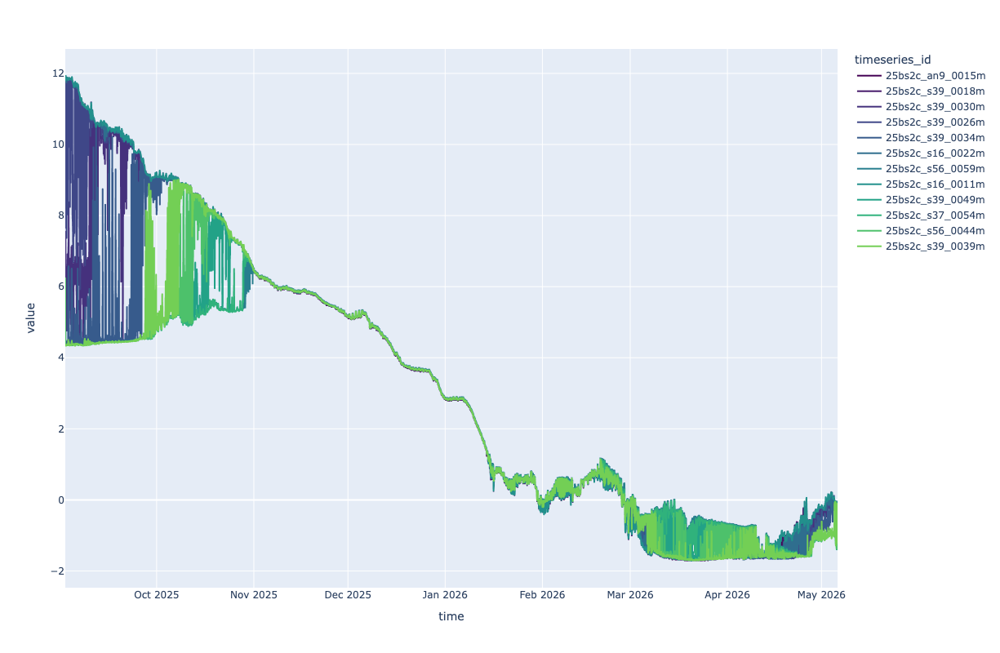

In [96]:
px.line(tdf.dropna(subset=['temperature'],how='all'),
        x='time',
        y=['temperature'],
        color='timeseries_id', 
        color_discrete_sequence=colors, width=1200, height=800)

In [97]:
colors = px.colors.sample_colorscale("viridis", 3)

px.line(tdf.dropna(subset=['salinity'],how='all'),
        x='time',
        y=['salinity'],
        color='timeseries_id', 
        color_discrete_sequence=colors)

In [98]:
colors = px.colors.sample_colorscale("viridis", 10)

px.line(tdf.dropna(subset=['pressure'],how='all'),
        x='time',
        y=['pressure'],
        color='timeseries_id', 
        color_discrete_sequence=colors)

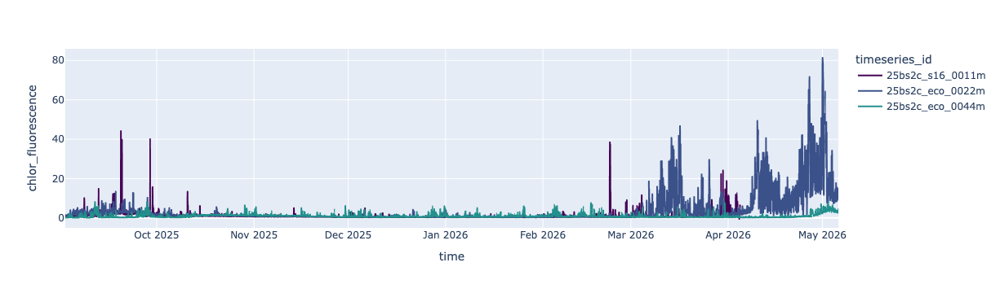

In [99]:
colors = px.colors.sample_colorscale("viridis", 5)

px.line(tdf.dropna(subset='chlor_fluorescence',how='all').sort_values(['depth','time']),
        x='time',
        y='chlor_fluorescence',
        color='timeseries_id',
        color_discrete_sequence=colors)

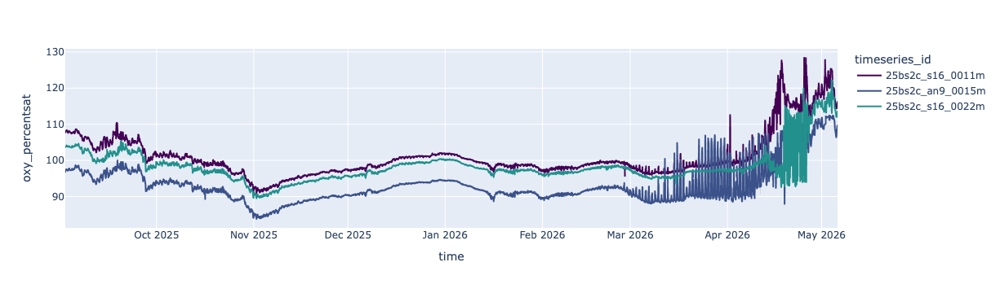

In [100]:
colors = px.colors.sample_colorscale("viridis", 5)

px.line(tdf.dropna(subset='oxy_percentsat',how='all').sort_values(['depth','time']),
        x='time',
        y='oxy_percentsat',
        color='timeseries_id',
        color_discrete_sequence=colors)

In [79]:
colors = px.colors.sample_colorscale("viridis", 4)

px.line(tdf.dropna(subset=['oxy_conc','oxy_conc_umkg'],how='all'),
        x='time',
        y=['oxy_conc','oxy_conc_umkg'],
        color='timeseries_id',
        color_discrete_sequence=colors)

In [80]:
colors = px.colors.sample_colorscale("viridis", 4)

px.line(tdf.dropna(subset='nitrate',how='all'),
        x='time',
        y='nitrate',
        color='timeseries_id',
        color_discrete_sequence=colors)

KeyError: ['nitrate']

In [ ]:
colors = px.colors.sample_colorscale("viridis", 4)

px.line(tdf.dropna(subset='par',how='all'),
        x='time',
        y='par',
        color='timeseries_id',
        color_discrete_sequence=colors)

In [ ]:
# file/var output
output = True

if output:
    
    tdf[['time','depth','latitude','longitude','temperature','timeseries_id']].dropna(subset='temperature',how='all').to_csv('25bs2c.temperature.csv')
    tdf[['time','depth','latitude','longitude','salinity','timeseries_id']].dropna(subset='salinity',how='all').to_csv('25bs2c.salinity.csv')
    
    vname = 'temperature'
    with pd.ExcelWriter(f'25bs2c_{vname}.xlsx') as writer:  
    
        for depthkey in tdf.groupby('depth').groups.keys():
            if not (tdf.groupby('depth').get_group(depthkey).dropna(how='all'))[vname].empty:
                try:
                    print(f'saving {depthkey}')
                    (tdf.groupby('depth').get_group(depthkey).dropna(how='all',axis=1))[['time',vname,'timeseries_id']].to_excel(writer, sheet_name=str(depthkey))
                except:
                    pass
    
    tdf.groupby('depth').get_group(depthkey).dropna(how='all',axis=1)